In [264]:
#Setup and Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification , make_moons, make_circles, load_breast_cancer, load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, SVR
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score


In [265]:
#create toy datasts

X_lin, y_lin= make_classification(
    n_samples=200,
    n_features=2,
    n_redundant=0,
    n_informative=2,
    n_clusters_per_class=1,
    class_sep=1.8,
    random_state=42,
)

y_lin[:10]

array([1, 1, 1, 1, 1, 0, 1, 0, 0, 0])

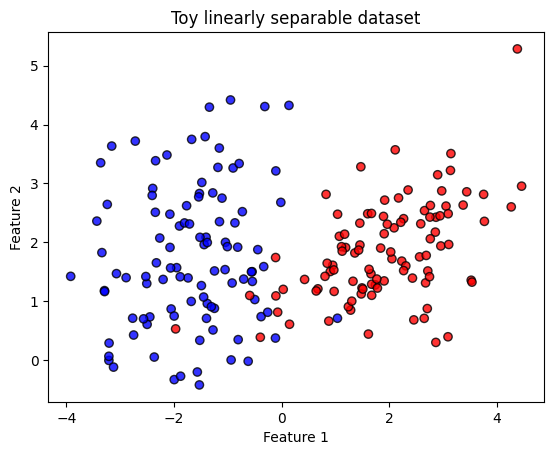

In [266]:
# Visualise the toy dataset
plt.scatter(X_lin[:,0],X_lin[:,1],c=y_lin, cmap='bwr', edgecolors='k', alpha=0.8)
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Toy linearly separable dataset')
plt.show()

In [267]:
# Split and scale the data
X_train, X_test, y_train, y_test= train_test_split( X_lin, y_lin, test_size=0.2, random_state=42)

#standarscaller
scaled= StandardScaler()
X_train_scaled=scaled.fit_transform(X_train)
x_test_scaled=scaled.transform(X_test)

In [268]:
#model train
svm_linear= SVC(kernel='linear', C=1.0, random_state=42)
svm_linear.fit(X_train_scaled, y_train)

#predict
y_test_pred= svm_linear.predict(x_test_scaled)
print('Accuracy',accuracy_score(y_test, y_test_pred))


Accuracy 0.975


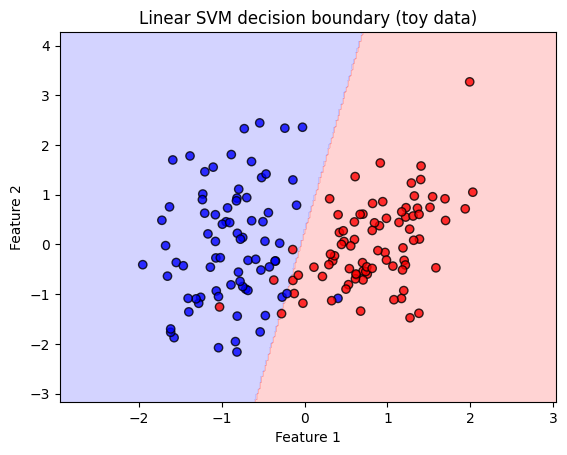

In [269]:
#helper for decision bonundary
def dicision_boundaey_plot (model, X, y, title='linear svm'):
  #min max calculate for graph pading
  x_min, x_max= X[:,0].min() -1 , X[:,0].max() +1
  y_min, y_max= X[:,1].min() -1 , X[:,1].max() +1
  #meshgrid for full graph xymin xymax(300x300)
  xx,yy=np.meshgrid(
      np.linspace(x_min,x_max,300),
      np.linspace(y_min,y_max,300)
  )

  #1d
  grid=np.c_[xx.ravel(),yy.ravel()]
  #predict
  Z=model.predict(grid)
  #return3d
  Z=Z.reshape(xx.shape)
  #plot decision onudary
  plt.contourf(xx,yy,Z, cmap='bwr', alpha=0.2)
  #points plot
  plt.scatter(X[:,0], X[:,1], c=y, alpha=0.8, cmap='bwr',edgecolors='k')

  plt.title(title)
  plt.xlabel('Feature 1')
  plt.ylabel('Feature 2')
  plt.show()

# Visualise the linear SVM boundary on scaled training data
dicision_boundaey_plot(svm_linear, X_train_scaled, y_train, title='Linear SVM decision boundary (toy data)')

#Kernels: Linear, Polynomial, and RBF

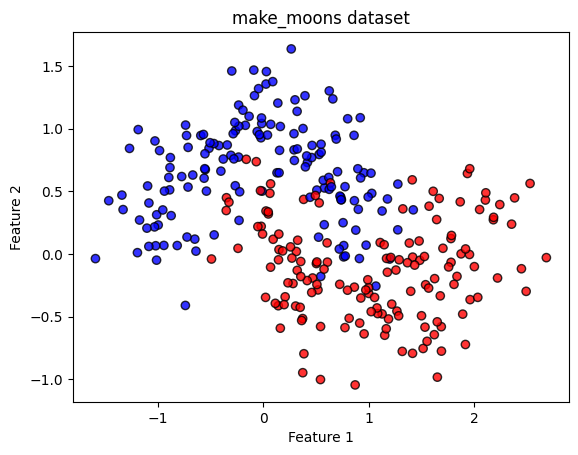

In [270]:
#generate moon datasets( non linear but simple)
X_moon, y_moon, =make_moons( n_samples=300, noise=0.25, random_state=42)
plt.scatter(X_moon[:,0],X_moon[:,1], c=y_moon, cmap='bwr', edgecolors='k', alpha=0.8)
plt.title('make_moons dataset')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.show()


accuracy 0.8833333333333333


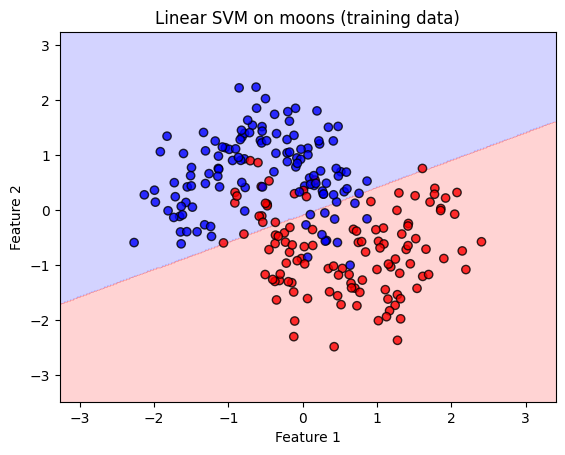

In [271]:

#train test spit
X_train_moon, X_test_moon, y_train_moon, y_test_moon= train_test_split(X_moon, y_moon, test_size=0.2, random_state=42)

#scaler
scaler_moon=StandardScaler()
X_train_scaled_moon= scaler_moon.fit_transform(X_train_moon)
X_test_scaled_moon=scaler_moon.transform(X_test_moon)

#model train
svc_linear_moon= SVC( kernel='linear', C=1.0, random_state=42)
svc_linear_moon.fit(X_train_scaled_moon, y_train_moon)

#predict
y_test_pred=svc_linear_moon.predict(X_test_scaled_moon)
print('accuracy',accuracy_score(y_test_moon, y_test_pred))


#disision bonundary
dicision_boundaey_plot(svc_linear_moon,X_train_scaled_moon, y_train_moon, title='Linear SVM on moons (training data)')

accuracy 0.9


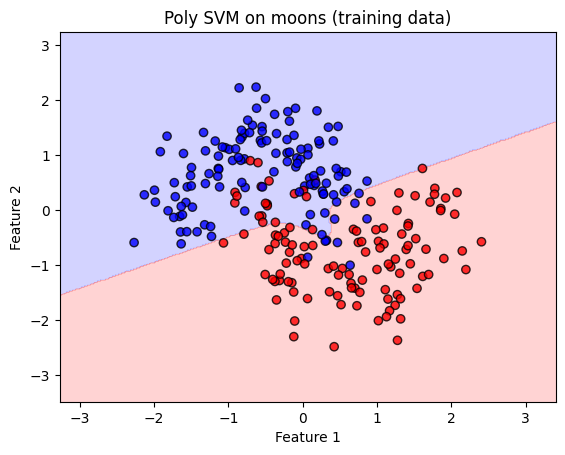

In [272]:
# Polynomial kernel on moons
svc_poly_moon= SVC(kernel='poly', degree=3, C=20.0, gamma='scale', random_state=42)
svc_poly_moon.fit(X_train_scaled_moon, y_train_moon)

#predict
y_test_pred_poly=svc_poly_moon.predict(X_test_scaled_moon)
print('accuracy',accuracy_score(y_test_moon, y_test_pred_poly))

#disision bonundary
dicision_boundaey_plot(svc_poly_moon,X_train_scaled_moon, y_train_moon, title='Poly SVM on moons (training data)')

accuracy 0.9333333333333333


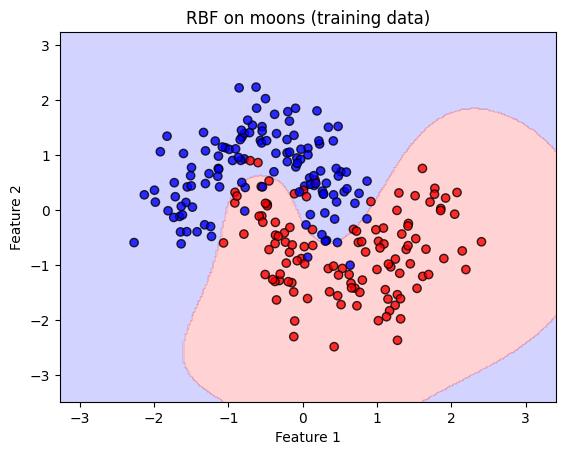

In [273]:
# RBF kernel on moons
svc_rbf_moon= SVC(kernel='rbf', degree=3, C=20.0, gamma='scale', random_state=42)
svc_rbf_moon.fit(X_train_scaled_moon, y_train_moon)

#predict
y_test_pred_rbf=svc_rbf_moon.predict(X_test_scaled_moon)
print('accuracy',accuracy_score(y_test_moon, y_test_pred_rbf))

#disision bonundary
dicision_boundaey_plot(svc_rbf_moon,X_train_scaled_moon, y_train_moon, title='RBF on moons (training data)')

In [274]:
#imort libries
#create datsets
#visuale toy datasets
#train test split
#standarscale
#model train
#predict


###helper function for decision boundary####
# helper function for decision boundary for 2d
#minmax for all feature pading
# useing full graph( min max )300 point for meshgrid/grid (300x300)
# ravel use for 1d array
#0/1 predict
# repeat 3d
#color decision bonundary
#points show



#helper
#minmax for all pading
#meshgrid for full graph
#ravel for 1d array xx,yy
#predict r1d
#retun 2d reshaape
#color dicision bonddary
#color oints